# Лабораторная работа №2. Кластеризация качества воздуха

**Цель.** Найти группы наблюдений «станция за день» с похожими профилями загрязнения. Откройте ноутбук в Jupyter или VS Code, выберите ядро Python с `pandas`, `numpy`, `matplotlib`, `scipy` и `scikit-learn` и запустите все ячейки по порядку.

По заданию сравниваем K-Means, DBSCAN и иерархическую кластеризацию, затем изучаем состав групп и их устойчивость. Размер выборки, метрики и правила выбора параметров ниже — решения для этого эксперимента.

## 1. Загрузка и очистка данных

Используем `station_day.csv` из папки второй лабораторной. Как в первой работе, исключаем `Xylene` из-за большой доли пропусков. Удаляем полные дубликаты и строки с пропусками в оставшихся 11 показателях. Наблюдения с пропуском в `AQI_Bucket` можно кластеризовать. При сравнении с известными категориями мы пропустим такие строки.

Генератор для общей подготовки данных находится в [первой лабораторной](../1laba/generate_data.py). Здесь исследуем плотность и состав групп реальных наблюдений. Искусственные точки добавим только в отдельном эксперименте с DBSCAN.

In [1]:
from itertools import combinations
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEED = 42
SAMPLE_SIZE = 3000

csv_path = Path("station_day.csv")
if not csv_path.is_file():
    csv_path = Path("2laba") / csv_path

raw = pd.read_csv(csv_path)
features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene",
]
clean = raw.drop_duplicates().dropna(subset=features)
data = clean.sample(n=min(SAMPLE_SIZE, len(clean)), random_state=SEED)
data = data.reset_index(drop=True)

print(f"Исходных строк: {len(raw):,}. После очистки: {len(clean):,}.")
print(f"В выборке: {len(data):,} строк, {len(features)} признаков.")
print(f"Станций после очистки: {clean['StationId'].nunique()}, в выборке: {data['StationId'].nunique()}.")
print(f"Доля пропусков в Xylene: {raw['Xylene'].isna().mean():.1%}")
display(data[features].head())

Исходных строк: 108,035. После очистки: 36,564.
В выборке: 3,000 строк, 11 признаков.
Станций после очистки: 58, в выборке: 57.
Доля пропусков в Xylene: 78.8%


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
0,41.96,264.12,40.75,102.54,95.68,32.99,1.66,34.89,60.61,1.24,0.81
1,15.93,49.77,4.85,24.85,15.54,8.48,0.12,5.72,22.14,1.97,6.44
2,165.79,347.04,30.63,62.25,58.04,40.17,2.14,18.84,39.87,2.99,17.16
3,123.67,261.61,178.13,92.17,194.25,37.61,2.78,15.40,47.75,8.31,61.51
4,42.29,89.45,12.04,50.54,36.64,53.61,1.33,11.90,47.53,2.30,23.64


### 1.1. Масштабирование

Алгоритмы сравнивают расстояния. Если один показатель принимает значения от 0 до 500, а другой от 0 до 2, первый может определять результат просто из-за масштаба. `StandardScaler` вычитает среднее каждого признака и делит на его стандартное отклонение. Типичный разброс становится сопоставимым, при этом экстремальные значения могут оставаться далеко от остальных.

Все методы получают одну матрицу `X` из случайной выборки. Размер 3 000 выбран для быстрого запуска, так как иерархический метод хранит попарные расстояния. Визуализация признаков и матрица корреляций для общей подготовки уже есть в [первой работе](../1laba/main.ipynb).

In [2]:
# В X входят только концентрации. Сохраняем исходные значения для интерпретации.
scaler = StandardScaler()
X = scaler.fit_transform(data[features])

## 2. K-Means

K-Means начинает с `k` центров. Каждый объект присоединяется к ближайшему центру, а затем центр пересчитывается как среднее объектов своей группы. Эти шаги повторяются. Начальные центры влияют на результат.

### 2.1. Подбираем число кластеров по силуэту

Силуэт сравнивает, насколько близок объект к своей группе и к ближайшей соседней группе. Значение ближе к 1 означает более чёткое разделение, около 0 — положение на границе, ниже 0 — возможное ошибочное отнесение. Выбираем максимум среднего силуэта среди `k` от 2 до 8. Для каждого `k` берём лучший по инерции из десяти запусков. Инерция — сумма квадратов расстояний до своих центров.

Выбранное k: 2. Средний силуэт: 0.467.


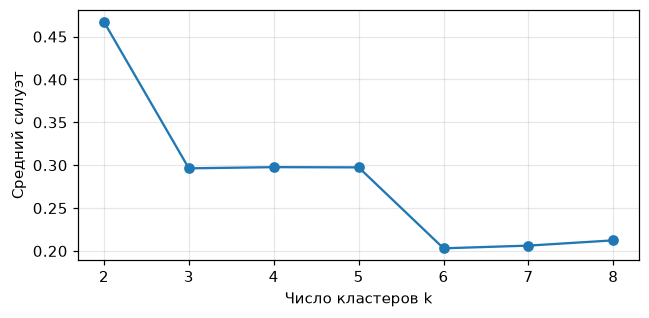

In [3]:
k_values = range(2, 9)
silhouettes = []
for k in k_values:
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    silhouettes.append(silhouette_score(X, labels))

best_k = k_values[int(np.argmax(silhouettes))]
print(f"Выбранное k: {best_k}. Средний силуэт: {max(silhouettes):.3f}.")

plt.figure(figsize=(6, 3))
plt.plot(k_values, silhouettes, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Число кластеров k")
plt.ylabel("Средний силуэт")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.2. Сравниваем инициализации

`random` выбирает начальные центры случайно. `k-means++` даёт преимущество точкам, далёким от уже выбранных центров. Для каждого способа выполняем пять отдельных запусков с разными seed и сравниваем среднюю инерцию и её разброс. `n_init=1` оставляет результат именно одного старта.

In [4]:
initializations = ["k-means++", "random"]
seeds = range(SEED, SEED + 5)

# Этот же набор запусков используем при проверке устойчивости ансамбля.
def kmeans_runs(values):
    return [
        KMeans(n_clusters=best_k, init=init, n_init=1, random_state=seed).fit(values)
        for init in initializations
        for seed in seeds
    ]

runs = kmeans_runs(X)
init_results = pd.DataFrame(
    {"Инициализация": model.init, "Инерция": model.inertia_} for model in runs
)
display(init_results.groupby("Инициализация")["Инерция"].agg(["min", "mean", "std"]).round(2))

,min,mean,std
Инициализация,,,
k-means++,22518.03,22518.33,0.21
random,22518.28,22518.38,0.14


### 2.3. Объединяем запуски в ансамбль

Номера кластеров произвольны. Одна и та же группа может получить номер 0 в одном запуске и номер 1 в другом. Берём запуск с минимальной инерцией как ориентир для нумерации. Для каждого запуска строим таблицу пересечений групп и подбираем взаимно однозначное соответствие номеров с максимальным общим числом совпавших объектов. После этого каждой строке назначаем номер, за который проголосовало больше запусков. При равенстве голосов побеждает меньший номер.

In [5]:
def ensemble_labels(models):
    reference = min(models, key=lambda model: model.inertia_).labels_
    votes = np.zeros((len(reference), best_k), dtype=int)
    rows = np.arange(len(reference))

    for model in models:
        labels = model.labels_
        # Строки таблицы — номера текущего запуска, столбцы — номера ориентира.
        overlaps = np.zeros((best_k, best_k), dtype=int)
        np.add.at(overlaps, (labels, reference), 1)
        current_ids, reference_ids = linear_sum_assignment(overlaps, maximize=True)
        mapping = np.empty(best_k, dtype=int)
        mapping[current_ids] = reference_ids
        votes[rows, mapping[labels]] += 1

    return votes.argmax(axis=1)

labels_kmeans = min(runs, key=lambda model: model.inertia_).labels_
labels_ensemble = ensemble_labels(runs)
print(f"Доля одинаковых назначений одиночного K-Means и ансамбля: "
      f"{np.mean(labels_kmeans == labels_ensemble):.1%}")

Доля одинаковых назначений одиночного K-Means и ансамбля: 99.9%


## 3. DBSCAN

DBSCAN ищет области высокой плотности. В радиусе `eps` вокруг ядра кластера должно быть хотя бы `min_samples` точек с учётом самой точки. Группы образуются вокруг связанных ядер. Точки, которые не попали ни в одну группу, получают метку шума `-1`.

### 3.1. Подбираем параметры по k-расстояниям

Пробуем `min_samples` 5, 11 и 22. Для каждого значения сортируем расстояния до последнего из нужного числа соседей, считая саму точку первым соседом. Резкий рост кривой показывает переход от плотной области к более разреженным точкам.

Чтобы воспроизводимо предложить `eps`, ищем максимальный отступ кривой вниз от диагонали после приведения обеих осей к интервалу от 0 до 1. При поиске перегиба пропускаем верхний 1% расстояний, чтобы несколько экстремальных точек не определяли наклон диагонали. На графике виден весь ряд расстояний.

Среди разбиений с минимум двумя кластерами выбираем максимальный силуэт по точкам, отнесённым к кластерам. Сначала рассматриваем варианты, которые покрывают хотя бы 80% выборки. Если таких нет, сравниваем все варианты с вычислимым силуэтом. Покрытие выводим рядом, потому что высокий силуэт на малой части данных сложно сравнивать с результатом по всей выборке.

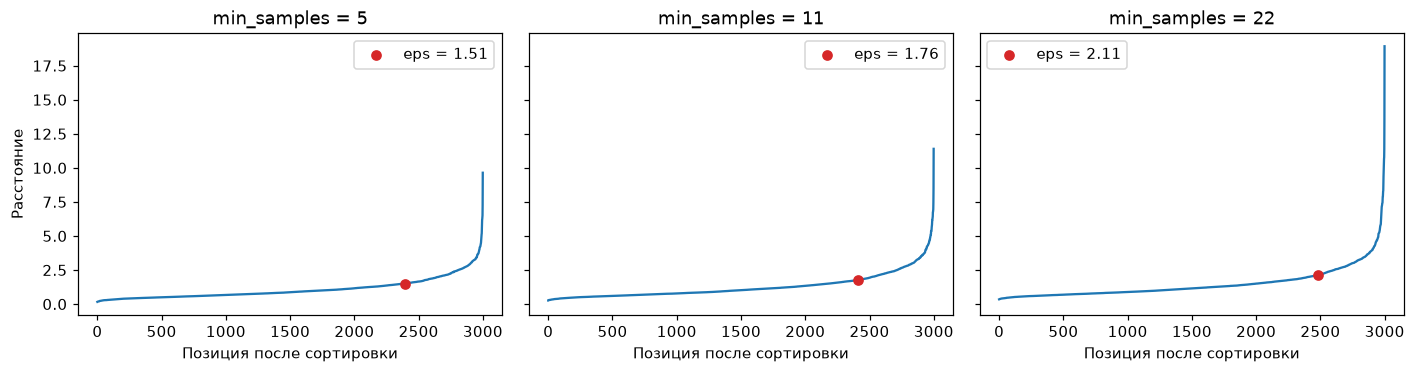

,min_samples,eps,Кластеров,Покрытие,Силуэт
0,5,1.509,5,0.849,0.199
1,11,1.759,1,0.866,NaN
2,22,2.109,1,0.890,NaN


Выбрано: eps = 1.509, min_samples = 5.


In [6]:
db_candidates = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)

for min_samples, ax in zip([5, 11, 22], axes):
    neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X)
    distances, _ = neighbors.kneighbors(X)
    k_distances = np.sort(distances[:, -1])

    body = k_distances[:int(0.99 * len(X))]
    positions = np.linspace(0, 1, len(body))
    scaled_distances = (body - body[0]) / (body[-1] - body[0])
    knee = int(np.argmax(positions - scaled_distances))
    eps = float(body[knee])

    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    assigned = labels != -1
    n_clusters = len(np.unique(labels[assigned]))
    score = np.nan
    if 2 <= n_clusters < assigned.sum():
        score = silhouette_score(X[assigned], labels[assigned])

    db_candidates.append({
        "min_samples": min_samples,
        "eps": eps,
        "Кластеров": n_clusters,
        "Покрытие": assigned.mean(),
        "Силуэт": score,
    })

    ax.plot(k_distances)
    ax.scatter(knee, eps, color="tab:red", zorder=3, label=f"eps = {eps:.2f}")
    ax.set_title(f"min_samples = {min_samples}")
    ax.set_xlabel("Позиция после сортировки")
    ax.legend()

axes[0].set_ylabel("Расстояние")
fig.tight_layout()
plt.show()

db_table = pd.DataFrame(db_candidates)
display(db_table.round(3))
valid = db_table.dropna(subset=["Силуэт"])
covered = valid[valid["Покрытие"] >= 0.80]
if not covered.empty:
    best_db = covered.loc[covered["Силуэт"].idxmax()]
elif not valid.empty:
    best_db = valid.loc[valid["Силуэт"].idxmax()]
else:
    # Если каждый вариант вырожден, сохраняем вариант с наибольшим покрытием.
    best_db = db_table.loc[db_table["Покрытие"].idxmax()]

db_eps = float(best_db["eps"])
db_min_samples = int(best_db["min_samples"])
labels_dbscan = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit_predict(X)
print(f"Выбрано: eps = {db_eps:.3f}, min_samples = {db_min_samples}.")

### 3.2. Проверяем чувствительность к шуму и выбросам

По отдельности добавляем два набора искусственных точек. **Фоновый шум** распределяем равномерно между 10-м и 90-м процентилями каждого признака. Такие комбинации нарушают исходные связи между признаками. **Далёкие выбросы** создаём выше максимума по каждой координате, с запасом больше `eps`. Работаем в масштабированных координатах, параметры DBSCAN и масштабирование фиксируем.

После добавления снова запускаем DBSCAN и сравниваем метки исходных наблюдений с базовым запуском через ARI. Эта метрика сравнивает два разбиения с поправкой на случайные совпадения. Она равна 1 для одинаковых разбиений с любой нумерацией, около 0 при совпадении на уровне случайности и может быть отрицательной. Для расчёта ARI метку `-1` учитываем как отдельную категорию.

In [7]:
rng = np.random.default_rng(SEED)
n_added = len(X) // 20  # Добавляем 5% от размера исходной выборки.
low, high = np.quantile(X, [0.10, 0.90], axis=0)
background = rng.uniform(low, high, size=(n_added, X.shape[1]))
far_outliers = X.max(axis=0) + db_eps + rng.uniform(1, 10, size=background.shape)

sensitivity = []
for name, added in [("База", X[:0]), ("Фоновый шум", background), ("Далёкие выбросы", far_outliers)]:
    labels = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit_predict(np.vstack([X, added]))
    original_labels = labels[:len(X)]
    sensitivity.append({
        "Сценарий": name,
        "Кластеров среди исходных": len(set(original_labels) - {-1}),
        "Шум среди исходных, %": 100 * np.mean(original_labels == -1),
        "Шум среди добавленных, %": 100 * np.mean(labels[len(X):] == -1) if len(added) else np.nan,
        "ARI с базой на исходных": adjusted_rand_score(labels_dbscan, original_labels),
    })

display(pd.DataFrame(sensitivity).round(3))

,Сценарий,Кластеров среди исходных,"Шум среди исходных, %","Шум среди добавленных, %",ARI с базой на исходных
0,База,5,15.133,NaN,1.000
1,Фоновый шум,4,15.033,6.667,0.989
2,Далёкие выбросы,5,15.133,100.000,1.000


## 4. Иерархическая кластеризация

В начале каждая точка образует отдельную группу. На каждом шаге объединяем две ближайшие группы. Используем **среднюю связь** (`average`): расстояние между группами равно среднему расстоянию между всеми парами точек из этих групп.

### 4.1. Сравниваем две метрики и разрезаем дендрограммы

Евклидово расстояние измеряет длину прямой между точками. Манхэттенское складывает абсолютные разности координат. Способ объединения групп оставляем одинаковым, чтобы сравнить именно метрики.

На дендрограмме высота соединения показывает расстояние между группами в момент слияния. Для каждого дерева ищем самый большой вертикальный промежуток между соседними уровнями слияния среди разрезов на 2–10 групп. Проводим линию посередине этого промежутка. График показывает последние 12 ветвей, чтобы верхние слияния были видны. Числа в скобках показывают, сколько наблюдений скрыто в свёрнутой ветви.

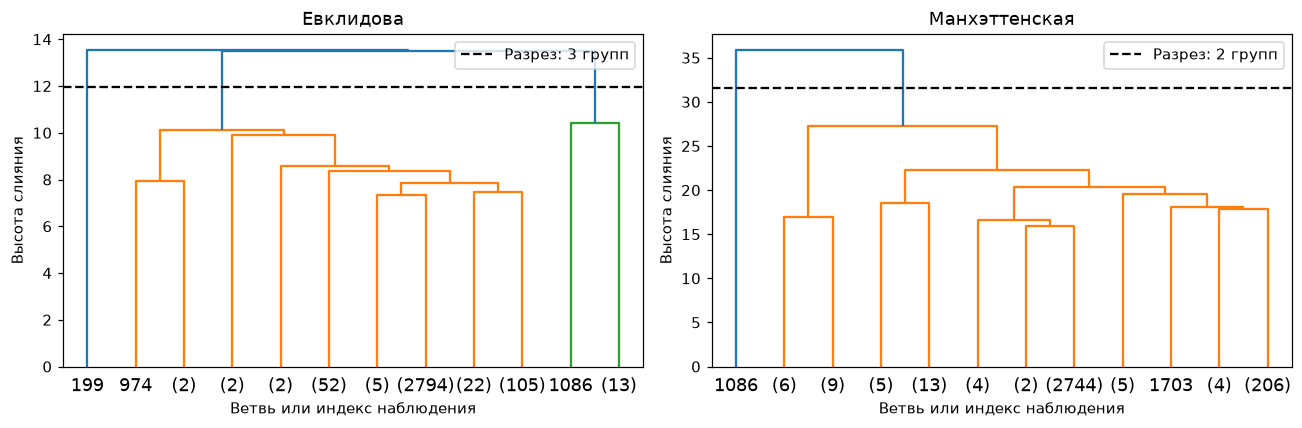

Евклидова метрика, размеры групп: [2985    1   14]
Манхэттенская метрика, размеры групп: [2999    1]
ARI между двумя разбиениями: 0.124


In [8]:
distances_to_compare = {"Евклидова": "euclidean", "Манхэттенская": "cityblock"}
hierarchy_labels = {}
hierarchy_k = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for (name, metric), ax in zip(distances_to_compare.items(), axes):
    tree = linkage(X, method="average", metric=metric)
    heights = tree[-10:, 2][::-1]  # Смотрим на последние слияния сверху вниз.
    gap_index = int(np.argmax(heights[:-1] - heights[1:]))
    k = gap_index + 2
    cut_height = (heights[gap_index] + heights[gap_index + 1]) / 2

    hierarchy_k[name] = k
    hierarchy_labels[name] = cut_tree(tree, n_clusters=k).ravel()
    dendrogram(tree, truncate_mode="lastp", p=12, color_threshold=cut_height, ax=ax)
    ax.axhline(cut_height, color="black", linestyle="--", label=f"Разрез: {k} групп")
    ax.set_title(name)
    ax.set_xlabel("Ветвь или индекс наблюдения")
    ax.set_ylabel("Высота слияния")
    ax.legend()

fig.tight_layout()
plt.show()

for name, labels in hierarchy_labels.items():
    print(f"{name} метрика, размеры групп:", np.bincount(labels))
print(f"ARI между двумя разбиениями: "
      f"{adjusted_rand_score(*hierarchy_labels.values()):.3f}")

### 4.2. Измеряем время при увеличении объёма данных

Используем первые 500, 1 000, 2 000 и 3 000 строк уже перемешанной выборки. Для каждой пары «размер и метрика» берём медиану трёх замеров построения дерева. Время отрисовки графиков не входит в замер. Число пар точек растёт примерно как квадрат размера выборки. Сравните, во сколько раз увеличилось время на вашем компьютере.

Метрика,Евклидова,Манхэттенская
Строк,,
500,0.0023,0.0022
1000,0.0115,0.0109
2000,0.0492,0.0508
3000,0.1368,0.1348


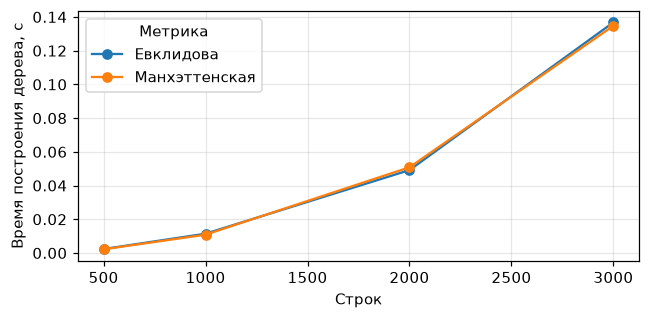

In [9]:
timings = []
for size in [500, 1000, 2000, 3000]:
    if size > len(X):
        continue

    for name, metric in distances_to_compare.items():
        elapsed = []
        for _ in range(3):
            start = perf_counter()
            linkage(X[:size], method="average", metric=metric)
            elapsed.append(perf_counter() - start)

        timings.append({"Строк": size, "Метрика": name, "Секунды": np.median(elapsed)})

time_table = pd.DataFrame(timings).pivot(index="Строк", columns="Метрика", values="Секунды")
display(time_table.round(4))
ax = time_table.plot(marker="o", figsize=(6, 3))
ax.set_ylabel("Время построения дерева, с")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Оценка разбиений

### 5.1. Сравнение с известными категориями качества воздуха

Считаем ARI относительно `AQI_Bucket` только там, где категория известна. У одного кластера может оказаться несколько категорий. В таблице видны их доли среди размеченных строк внутри каждой группы. Размер группы считается по всем строкам. Для DBSCAN метку шума выделяем отдельно. В общей таблице также считаем ARI для DBSCAN только по точкам, которым он назначил кластер. Этот показатель относится к меньшей части данных, поэтому его нужно читать вместе с покрытием.

In [10]:
partitions = {
    "K-Means": labels_kmeans,
    "Ансамбль K-Means": labels_ensemble,
    "DBSCAN": labels_dbscan,
    **{f"Иерархическая: {name.lower()}": labels for name, labels in hierarchy_labels.items()},
}
known = data["AQI_Bucket"].notna().to_numpy()
buckets = data.loc[known, "AQI_Bucket"]
class_order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
comparison = []

for name, labels in partitions.items():
    assigned = labels != -1
    known_assigned = known & assigned
    comparison.append({
        "Метод": name,
        "Кластеров": len(np.unique(labels[assigned])),
        "Покрытие, %": 100 * assigned.mean(),
        "ARI на всех размеченных": adjusted_rand_score(buckets, labels[known]),
        "ARI на размеченных в кластерах": (
            adjusted_rand_score(data.loc[known_assigned, "AQI_Bucket"], labels[known_assigned])
            if known_assigned.sum() >= 2 else np.nan
        ),
    })

print(f"Известная категория есть у {known.sum()} из {len(data)} наблюдений.")
display(pd.DataFrame(comparison).set_index("Метод").round(3))

for name, labels in partitions.items():
    class_pct = pd.crosstab(labels[known], buckets.to_numpy(), normalize="index") * 100
    sizes = pd.Series(labels).value_counts().sort_index().rename("Размер")
    class_pct = class_pct.reindex(columns=class_order, fill_value=0)
    print(name)
    display(sizes.to_frame().join(class_pct).rename_axis("Группа").round(1))

Известная категория есть у 2933 из 3000 наблюдений.


,Кластеров,"Покрытие, %",ARI на всех размеченных,ARI на размеченных в кластерах
Метод,,,,
K-Means,2,100.000,0.156,0.156
Ансамбль K-Means,2,100.000,0.155,0.155
DBSCAN,5,84.867,0.099,0.005
Иерархическая: евклидова,3,100.000,0.000,0.000
Иерархическая: манхэттенская,2,100.000,0.000,0.000


K-Means


,Размер,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Группа,,,,,,,
0,2361,9.1,29.7,43.5,11.8,5.3,0.5
1,639,0.2,0.3,11.8,18.0,40.5,29.3


Ансамбль K-Means


,Размер,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Группа,,,,,,,
0,2365,9.1,29.7,43.4,11.8,5.5,0.5
1,635,0.2,0.3,11.8,18.1,40.3,29.4


... (2 outputs left out)

Иерархическая: евклидова


,Размер,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Группа,,,,,,,
0,2985,7.1,23.5,36.7,13.1,13.0,6.7
1,1,0.0,0.0,0.0,0.0,0.0,100.0
2,14,28.6,14.3,42.9,14.3,0.0,0.0


Иерархическая: манхэттенская


,Размер,Good,Satisfactory,Moderate,Poor,Very Poor,Severe
Группа,,,,,,,
0,2999,7.2,23.4,36.7,13.1,12.9,6.7
1,1,100.0,0.0,0.0,0.0,0.0,0.0


### 5.2. Экспертная оценка по профилям загрязнения

Смотрим, какие показатели типичны для каждой группы. Считаем медианы по всем 11 признакам в исходном масштабе. Медиана — середина упорядоченного ряда, поэтому отдельное экстремальное значение влияет на неё слабее, чем на среднее. Строка «Вся выборка» служит ориентиром. Сравнивайте значения **внутри одного столбца**. Например, более высокие медианы PM2.5 и PM10 могут указывать на группу с более выраженным загрязнением частицами. Размер группы помогает отличить распространённый профиль от редкого случая.

In [11]:
overall = data[features].median().rename("Вся выборка").to_frame().T
overall.insert(0, "Размер", len(data))
profiles = {}

for name, labels in partitions.items():
    groups = data[features].groupby(labels)
    profile = groups.median()
    profile.insert(0, "Размер", groups.size())
    profiles[name] = profile

    print(name)
    display(pd.concat([overall, profile]).rename_axis("Группа").round(2))

K-Means


,Размер,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Группа,,,,,,,,,,,,
Вся выборка,3000,55.62,124.15,10.92,34.39,31.34,25.03,0.91,10.66,31.76,1.97,9.54
0,2361,44.47,102.58,7.79,27.63,25.05,21.39,0.76,9.44,31.44,1.38,6.88
1,639,163.61,319.19,66.01,74.72,106.03,42.17,1.93,18.84,32.81,6.78,36.46


Ансамбль K-Means


,Размер,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Группа,,,,,,,,,,,,
Вся выборка,3000,55.62,124.15,10.92,34.39,31.34,25.03,0.91,10.66,31.76,1.97,9.54
0,2365,44.57,102.59,7.81,27.65,25.10,21.41,0.76,9.44,31.51,1.38,6.88
1,635,163.61,319.49,66.26,74.72,106.45,42.24,1.94,18.88,32.76,6.80,36.69


DBSCAN


,Размер,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Группа,,,,,,,,,,,,
Вся выборка,3000,55.62,124.15,10.92,34.39,31.34,25.03,0.91,10.66,31.76,1.97,9.54
-1,454,181.17,341.94,65.94,75.30,106.57,46.76,2.05,18.90,31.28,7.61,38.06
0,2527,47.82,109.62,8.95,29.83,27.04,22.82,0.81,9.87,31.90,1.58,7.76
1,6,211.44,358.00,171.84,86.38,187.20,51.66,2.74,12.83,13.95,7.64,48.62
2,5,148.82,148.82,29.62,77.88,109.23,41.18,1.17,22.86,279.49,1.06,3.76
3,4,85.70,85.70,23.80,53.92,51.30,40.74,1.44,14.78,217.64,7.95,64.59
4,4,35.08,81.06,18.04,38.76,152.45,31.59,0.73,13.18,12.75,1.40,4.86


Иерархическая: евклидова


,Размер,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Группа,,,,,,,,,,,,
Вся выборка,3000,55.62,124.15,10.92,34.39,31.34,25.03,0.91,10.66,31.76,1.97,9.54
0,2985,55.62,124.15,10.88,34.32,31.29,25.04,0.91,10.68,31.93,1.96,9.42
1,1,376.25,601.07,231.20,283.04,252.13,36.66,5.00,16.54,20.90,20.73,123.36
2,14,53.21,120.28,32.69,38.38,72.60,23.89,0.90,5.04,7.56,118.52,144.21


Иерархическая: манхэттенская


,Размер,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Группа,,,,,,,,,,,,
Вся выборка,3000,55.62,124.15,10.92,34.39,31.34,25.03,0.91,10.66,31.76,1.97,9.54
0,2999,55.62,124.15,10.92,34.41,31.34,25.03,0.91,10.66,31.77,1.97,9.53
1,1,8.58,12.38,0.99,2.84,1.14,2.91,0.22,8.62,1.45,205.43,205.43


#### Что видно в этой выборке

- **K-Means и ансамбль.** У меньшей группы K-Means медиана PM2.5 составляет 163,61 против 44,47 у большей группы. PM10 и NO тоже заметно выше, а медианы O3 близки. Это профиль с более высокими уровнями нескольких загрязнителей. Категории `Very Poor` и `Severe` вместе составляют около 70% размеченных наблюдений меньшей группы. При этом общий ARI с `AQI_Bucket` равен 0,156. Группы отражают различия в загрязнении и лишь частично совпадают с категориями качества воздуха.
- **DBSCAN.** Один плотный кластер содержит 2 527 из 3 000 наблюдений. Ещё четыре группы содержат по 4–6 наблюдений. Из 454 точек, отмеченных как шум, у многих высокие значения PM2.5 и PM10, а среди размеченных около 71% относятся к `Very Poor` или `Severe`. В данном случае метка шума означает редкий профиль по плотности, а высокие концентрации заслуживают отдельного внимания.
- **Иерархическая кластеризация.** При евклидовой метрике группа из 14 наблюдений выделяется высокими медианами Benzene и Toluene. Манхэттенская метрика при своём разрезе отделяет только одно наблюдение с высокими значениями этих показателей. В обоих случаях выбранный разрез выявляет редкие профили, а почти все остальные наблюдения остаются в одной группе.

### 5.3. Визуализация кластеров и категорий

Метод главных компонент (PCA) строит две новые координаты из всех 11 признаков. Они сохраняют как можно больше разброса для плоского рисунка. Алгоритмы кластеризации выше работали со всеми 11 признаками. Близость точек на рисунке показывает близость только в проекции. Цвета и номера кластеров читаются отдельно на каждом графике, шум DBSCAN выделен серым крестиком.

Две компоненты объясняют 58.4% разброса.


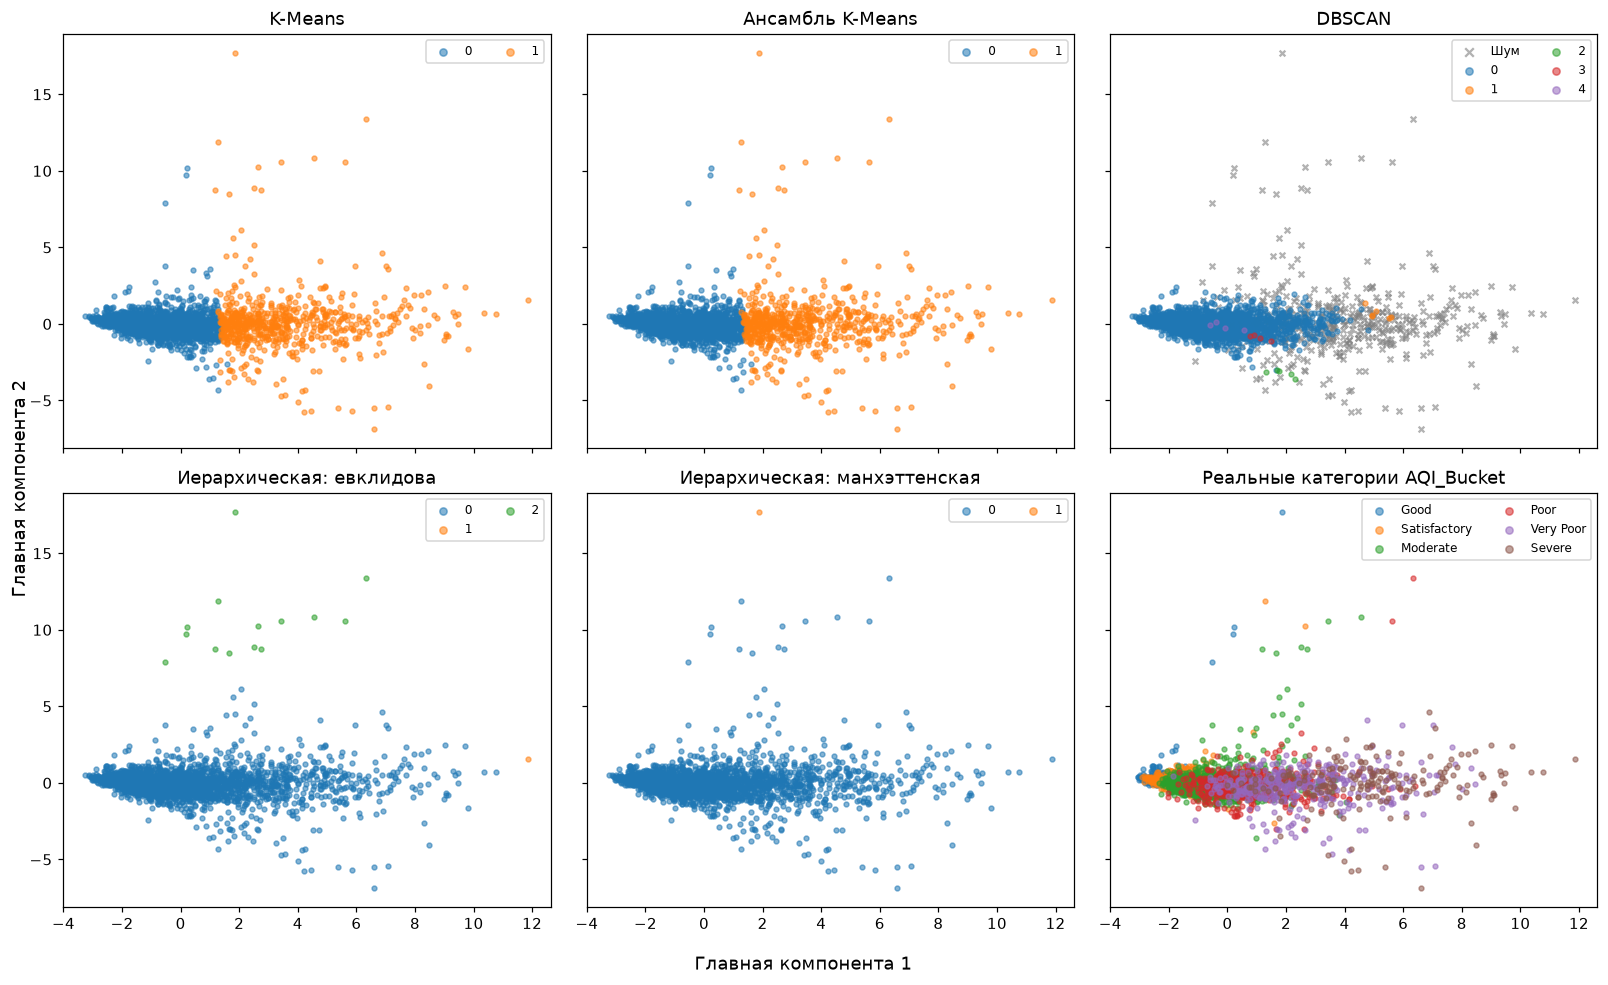

In [12]:
pca = PCA(n_components=2)
coordinates = pca.fit_transform(X)
print(f"Две компоненты объясняют {pca.explained_variance_ratio_.sum():.1%} разброса.")

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for (name, labels), ax in zip(partitions.items(), axes.flat):
    for cluster_id in np.unique(labels):
        points = coordinates[labels == cluster_id]
        if cluster_id == -1:
            ax.scatter(*points.T, color="gray", marker="x", s=14, alpha=0.6, label="Шум")
        else:
            ax.scatter(*points.T, s=10, alpha=0.55, label=str(cluster_id))

    ax.set_title(name)
    if len(np.unique(labels)) <= 10:
        ax.legend(markerscale=1.5, fontsize=8, ncol=2)

ax = axes.flat[-1]
for category in class_order:
    points = coordinates[data["AQI_Bucket"].eq(category).to_numpy()]
    ax.scatter(*points.T, s=10, alpha=0.55, label=category)
ax.set_title("Реальные категории AQI_Bucket")
ax.legend(markerscale=1.5, fontsize=8, ncol=2)
fig.supxlabel("Главная компонента 1")
fig.supylabel("Главная компонента 2")
fig.tight_layout()
plt.show()

### 5.4. Устойчивость на повторных подвыборках

Шесть раз случайно отбираем по 80% наблюдений без повторов внутри подвыборки. На каждой заново вычисляем параметры масштабирования и запускаем все методы с ранее выбранными гиперпараметрами. У DBSCAN и иерархического метода нет общего способа назначить кластер новым точкам. Поэтому для каждой пары запусков сравниваем через ARI только объекты, вошедшие в обе подвыборки.

Чем ближе средний ARI к 1 и меньше его разброс, тем чаще методы собирают одни и те же объекты вместе. Для DBSCAN шум входит в ARI как отдельная категория. Диапазон числа групп и доля назначенных точек помогают заметить случаи, когда высокий ARI получен на одном большом кластере или при большом объёме шума. Проверка оценивает устойчивость при изменении состава текущей выборки.

In [13]:
subsamples = []
rng = np.random.default_rng(SEED)
for _ in range(6):
    indices = np.sort(rng.choice(len(data), size=int(0.8 * len(data)), replace=False))
    values = StandardScaler().fit_transform(data.iloc[indices][features])
    models = kmeans_runs(values)

    fitted = {
        "K-Means": min(models, key=lambda model: model.inertia_).labels_,
        "Ансамбль K-Means": ensemble_labels(models),
        "DBSCAN": DBSCAN(eps=db_eps, min_samples=db_min_samples).fit_predict(values),
    }
    for name, metric in distances_to_compare.items():
        tree = linkage(values, method="average", metric=metric)
        fitted[f"Иерархическая: {name.lower()}"] = cut_tree(
            tree, n_clusters=hierarchy_k[name]
        ).ravel()

    subsamples.append(pd.DataFrame(fitted, index=indices))

pair_scores = []
for left, right in combinations(subsamples, 2):
    common = left.index.intersection(right.index)
    pair_scores.append({
        name: adjusted_rand_score(left.loc[common, name], right.loc[common, name])
        for name in partitions
    })

ari_pairs = pd.DataFrame(pair_scores)
stability = ari_pairs.agg(["mean", "std", "min"]).T
stability.columns = ["Средний ARI", "Разброс (ст. откл.)", "Минимальный ARI"]

for name in partitions:
    counts = [sample.loc[sample[name] != -1, name].nunique() for sample in subsamples]
    stability.loc[name, "Кластеров (мин–макс)"] = f"{min(counts)}–{max(counts)}"
    stability.loc[name, "Среднее покрытие, %"] = 100 * np.mean([
        sample[name].ne(-1).mean() for sample in subsamples
    ])

print(f"Сравнено {len(ari_pairs)} пар подвыборок.")
display(stability.round(3))

Сравнено 15 пар подвыборок.


,Средний ARI,Разброс (ст. откл.),Минимальный ARI,Кластеров (мин–макс),"Среднее покрытие, %"
K-Means,0.986,0.007,0.975,2–2,100.000
Ансамбль K-Means,0.987,0.005,0.977,2–2,100.000
DBSCAN,0.934,0.009,0.918,2–4,83.472
Иерархическая: евклидова,0.847,0.159,0.547,3–3,100.000
Иерархическая: манхэттенская,0.156,0.287,-0.006,2–2,100.000


## 6. Выводы по выполненному запуску

- **Инициализация K-Means.** Лучший по силуэту результат получился при `k = 2` (0,467). Средняя инерция двух способов старта почти совпала. Ансамбль сохранил 99,9% назначений лучшего одиночного запуска, а средний ARI на подвыборках составил 0,987 против 0,986. На этих данных выигрыш от ансамбля небольшой.
- **Чувствительность DBSCAN.** При `eps ≈ 1,509` и `min_samples = 5` модель выделила пять кластеров. Далёкие выбросы получили метку шума и сохранили исходное разбиение. При добавлении фоновых точек число кластеров среди исходных наблюдений уменьшилось с пяти до четырёх, хотя ARI с исходным разбиением остался высоким (0,989). Число групп показывает изменения малых кластеров, которые слабо влияют на общий ARI.
- **Масштабируемость иерархического метода.** При росте выборки с 500 до 3 000 строк время построения дерева увеличилось примерно с 0,002 до 0,135 секунды для обеих метрик на компьютере, где выполнен запуск. При повторных подвыборках средний ARI евклидова варианта (0,847) выше, чем манхэттенского (0,156). Во втором случае выбор одного редкого наблюдения сильно влияет на совпадение двух разбиений.

**Для самостоятельной проверки.** Сначала сопоставьте размеры групп с таблицей медиан. Затем поменяйте `SEED` в первой ячейке с кодом и снова запустите ноутбук сверху вниз. Проверьте, выделяет ли K-Means группу с повышенными PM2.5 и PM10 и меняется ли число малых групп DBSCAN. Числа в выводах относятся к сохранённому запуску с `SEED = 42`.